# UNESCO World Heritage Classification

## 1. Problem Definition

This project explores how data mining methods can be
applied to cultural heritage information.

The initial research question is:

Can descriptions of UNESCO World Heritage sites be used
to predict their official heritage categories?

## 2. Data Collection Plan

- Problem: Explore text classification for cultural heritage.
- Data type: Structured metadata and textual descriptions.
- Data source: UNESCO World Heritage List.
- Collection method: Python API requests.
- Analysis tool: Python and pandas.

**Make one API request**

In [1]:
import requests
from pprint import pprint

# UNESCO World Heritage List API
api_url = (
    "https://data.unesco.org/api/explore/v2.1/"
    "catalog/datasets/whc001/records"
)

# Request five records
response = requests.get(
    api_url,
    params={"limit": 5},
    timeout=30
)

# Check whether the request succeeded
print("Status code:", response.status_code)

# Stop if the server returned an HTTP error
response.raise_for_status()

# Convert the JSON response into a Python object
data = response.json()

# Inspect the response structure
print("\nResponse keys:")
print(list(data.keys()))

print("\nFirst record:")
pprint(data["results"][0])

Status code: 200

Response keys:
['total_count', 'results']

First record:
{'area_hectares': 70.0,
 'category': 'Cultural',
 'category_id': 1,
 'components_count': 1,
 'components_list': '[{"name": "Valley of Hari River including Minaret of '
                    'Jam", "ref": "211-001", "latitude": 34.3964166667, '
                    '"longitude": 64.5158888889}]',
 'coordinates': {'geometry': {'coordinates': [[64.5158888889, 34.3964166667]],
                              'type': 'MultiPoint'},
                 'properties': {},
                 'type': 'Feature'},
 'criteria_txt': '(ii)(iii)(iv)',
 'cultural_criteria': 'c2, c3, c4',
 'danger': 'True',
 'danger_list': 'Y 2002',
 'date_end': None,
 'date_inscribed': '2002',
 'description_en': 'The 65m-tall Minaret of Jam is a graceful, soaring '
                   'structure, dating back to the 12th century. Covered in '
                   'elaborate brickwork with a blue tile inscription at the '
                   'top, it is notewor

**Examine the five records using pandas**

In [2]:
import pandas as pd

# Extract the list of records from the API response
records = data["results"]

# Convert the records into a pandas DataFrame
sample_df = pd.DataFrame(records)

# Examine the dataset structure
print("Number of rows and columns:", sample_df.shape)

print("\nAvailable fields:")
print(sorted(sample_df.columns.tolist()))

# Inspect selected fields
fields_to_inspect = [
    "category",
    "description_en",
    "date_inscribed",
    "states_names"
]

# Select only fields that actually exist
available_fields = [
    field for field in fields_to_inspect
    if field in sample_df.columns
]

display(sample_df[available_fields])

Number of rows and columns: (5, 55)

Available fields:
['area_hectares', 'category', 'category_id', 'components_count', 'components_list', 'coordinates', 'criteria_txt', 'cultural_criteria', 'danger', 'danger_list', 'date_end', 'date_inscribed', 'description_en', 'geo_point_2d', 'id_no', 'images_urls', 'iso_codes', 'justification_en', 'main_image_author', 'main_image_caption_ar', 'main_image_caption_en', 'main_image_caption_es', 'main_image_caption_fr', 'main_image_caption_ru', 'main_image_caption_zh', 'main_image_copyright', 'main_image_url', 'main_video_author', 'main_video_caption_ar', 'main_video_caption_en', 'main_video_caption_es', 'main_video_caption_fr', 'main_video_caption_ru', 'main_video_caption_zh', 'main_video_url', 'name_ar', 'name_en', 'name_es', 'name_fr', 'name_ru', 'name_zh', 'natural_criteria', 'region', 'region_code', 'secondary_dates', 'short_description_ar', 'short_description_en', 'short_description_es', 'short_description_fr', 'short_description_ru', 'short_desc

,category,description_en,date_inscribed,states_names
0,Cultural,"The 65m-tall Minaret of Jam is a graceful, soa...",2002,[Afghanistan]
1,Cultural,The cultural landscape and archaeological rema...,2003,[Afghanistan]
2,Cultural,Berat and Gjirokastra are inscribed as rare ex...,2005,[Albania]
3,Natural,This transnational property includes 93 compon...,2007,"[North Macedonia, Spain, Italy, France, Poland..."
4,Cultural,"Situated 900 m above sea-level, Djémila, or Cu...",1982,[Algeria]


**Inspect the relevant fields**

In [3]:
# Select the key fields for our project
fields_to_review = [
    "name_en",
    "category",
    "short_description_en",
    "description_en",
    "date_inscribed",
    "states_names"
]

# Keep only fields that exist in the API response
available_fields = [
    field for field in fields_to_review
    if field in sample_df.columns
]

# Display site names, categories, dates, and countries
display(
    sample_df[
        [
            field for field in [
                "name_en",
                "category",
                "date_inscribed",
                "states_names"
            ]
            if field in sample_df.columns
        ]
    ]
)

# Compare the two English description fields
for field in ["short_description_en", "description_en"]:

    if field in sample_df.columns:
        descriptions = sample_df[field].dropna()

        print(f"\nField: {field}")
        print("Non-missing descriptions:", len(descriptions))

        if not descriptions.empty:
            print(
                "Average description length:",
                round(descriptions.str.len().mean(), 1),
                "characters"
            )

# Check missing values in the selected fields
print("\nMissing values in the five-record sample:")
print(sample_df[available_fields].isna().sum())

,name_en,category,date_inscribed,states_names
0,Minaret and Archaeological Remains of Jam,Cultural,2002,[Afghanistan]
1,Cultural Landscape and Archaeological Remains ...,Cultural,2003,[Afghanistan]
2,Historic Centres of Berat and Gjirokastra,Cultural,2005,[Albania]
3,Ancient and Primeval Beech Forests of the Carp...,Natural,2007,"[North Macedonia, Spain, Italy, France, Poland..."
4,Djémila,Cultural,1982,[Algeria]



Field: short_description_en
Non-missing descriptions: 5
Average description length: 492.6 characters

Field: description_en
Non-missing descriptions: 5
Average description length: 492.6 characters

Missing values in the five-record sample:
name_en                 0
category                0
short_description_en    0
description_en          0
date_inscribed          0
states_names            0
dtype: int64


**Compare the description fields**

In [4]:
# Compare the two description fields
short_text = (
    sample_df["short_description_en"]
    .fillna("")
    .str.strip()
)

full_text = (
    sample_df["description_en"]
    .fillna("")
    .str.strip()
)

# Check whether the descriptions match row by row
same_description = short_text == full_text

print(
    "Number of records with identical descriptions:",
    same_description.sum(),
    "out of",
    len(sample_df)
)

# Show the comparison for each site
comparison_df = pd.DataFrame({
    "Site name": sample_df["name_en"],
    "Short description length": short_text.str.len(),
    "Full description length": full_text.str.len(),
    "Descriptions identical": same_description
})

display(comparison_df)

Number of records with identical descriptions: 5 out of 5


,Site name,Short description length,Full description length,Descriptions identical
0,Minaret and Archaeological Remains of Jam,458,458,True
1,Cultural Landscape and Archaeological Remains ...,544,544,True
2,Historic Centres of Berat and Gjirokastra,795,795,True
3,Ancient and Primeval Beech Forests of the Carp...,469,469,True
4,Djémila,197,197,True


**Collect all UNESCO records**

In [5]:
# Collect all records from the UNESCO API

all_records = []
limit = 100
offset = 0
total_count = None

while True:
    # Request one batch of records
    response = requests.get(
        api_url,
        params={
            "limit": limit,
            "offset": offset
        },
        timeout=30
    )

    # Check whether the request succeeded
    response.raise_for_status()

    # Convert the JSON response into a Python dictionary
    page_data = response.json()

    # Get the total number of available records
    if total_count is None:
        total_count = page_data["total_count"]
        print("Total records available:", total_count)

    # Extract the records from this batch
    batch = page_data["results"]

    # Stop if the API returns no records
    if not batch:
        break

    # Add the new records to our collection
    all_records.extend(batch)

    # Update the offset for the next request
    offset += len(batch)

    print(f"Collected {len(all_records)} of {total_count} records")

    # Stop when all available records have been collected
    if offset >= total_count:
        break

# Convert the complete collection into a DataFrame
df = pd.DataFrame(all_records)

# Check the result
print("\nCollection completed.")
print("Dataset dimensions:", df.shape)
print("Total records collected:", len(df))

Total records available: 1273
Collected 100 of 1273 records
Collected 200 of 1273 records
Collected 300 of 1273 records
Collected 400 of 1273 records
Collected 500 of 1273 records
Collected 600 of 1273 records
Collected 700 of 1273 records
Collected 800 of 1273 records
Collected 900 of 1273 records
Collected 1000 of 1273 records
Collected 1100 of 1273 records
Collected 1200 of 1273 records
Collected 1273 of 1273 records

Collection completed.
Dataset dimensions: (1273, 55)
Total records collected: 1273


**Assess the quality of the complete dataset**

In [6]:
# Step 1: Confirm the dataset size
print("Dataset dimensions:", df.shape)

# Step 2: Check the fields relevant to our project
important_fields = [
    "uuid",
    "name_en",
    "category",
    "short_description_en",
    "description_en",
    "date_inscribed",
    "states_names"
]

available_fields = [
    field for field in important_fields
    if field in df.columns
]

print("\nFields available for analysis:")
print(available_fields)

# Step 3: Check missing values
print("\nMissing values:")
display(df[available_fields].isna().sum().to_frame("Missing values"))

# Step 4: Check blank descriptions
for field in ["short_description_en", "description_en"]:
    if field in df.columns:
        blank_count = (
            df[field].fillna("").astype(str).str.strip().eq("").sum()
        )
        print(f"Blank values in {field}: {blank_count}")

# Step 5: Check duplicate identifiers
if "uuid" in df.columns:
    print(
        "\nDuplicate UUIDs:",
        df["uuid"].duplicated().sum()
    )

# Step 6: Examine the official category distribution
category_counts = (
    df["category"]
    .value_counts(dropna=False)
    .rename_axis("Category")
    .reset_index(name="Count")
)

category_counts["Percentage"] = (
    category_counts["Count"] / len(df) * 100
).round(2)

print("\nCategory distribution:")
display(category_counts)

# Step 7: Compare the two description fields
short_text = df["short_description_en"].fillna("").astype(str).str.strip()
full_text = df["description_en"].fillna("").astype(str).str.strip()

print(
    "\nRecords with identical descriptions:",
    (short_text == full_text).sum(),
    "out of",
    len(df)
)

Dataset dimensions: (1273, 55)

Fields available for analysis:
['uuid', 'name_en', 'category', 'short_description_en', 'description_en', 'date_inscribed', 'states_names']

Missing values:


,Missing values
uuid,0
name_en,0
category,0
short_description_en,1
description_en,1
date_inscribed,0
states_names,0


Blank values in short_description_en: 1
Blank values in description_en: 1

Duplicate UUIDs: 0

Category distribution:


,Category,Count,Percentage
0,Cultural,991,77.85
1,Natural,240,18.85
2,Mixed,42,3.30



Records with identical descriptions: 1273 out of 1273


**Investigate the missing description**

In [7]:
# Find records with missing or blank descriptions
missing_description = df[
    df["description_en"].isna()
    | df["description_en"].fillna("").str.strip().eq("")
]

# Display the affected records
print("Records with missing descriptions:", len(missing_description))

display(
    missing_description[
        [
            "uuid",
            "name_en",
            "category",
            "date_inscribed",
            "states_names",
            "description_en"
        ]
    ]
)

Records with missing descriptions: 1


,uuid,name_en,category,date_inscribed,states_names,description_en
338,843cc2b1-38de-535b-80b4-9584cfb598a1,Sebastia,Cultural,2026,[State of Palestine],NaN


## Data Cleaning Decision: Missing Description

The original dataset contained 1,273 records.

One record, Sebastia, had a missing English description. Because the description is required as the input for text classification, this record was excluded from the analysis dataset.

The original dataset remains unchanged. The cleaned analysis dataset contains 1,272 records.

This decision preserves the original data while ensuring that every record used in text classification has usable input text.

In [8]:
# Identify records with usable English descriptions
has_description = (
    df["description_en"]
    .fillna("")
    .astype(str)
    .str.strip()
    .ne("")
)

# Create a separate dataset for text classification
analysis_df = df.loc[has_description].copy()

# Compare the original and analysis datasets
print("Original records:", len(df))
print("Records retained:", len(analysis_df))
print("Records excluded:", len(df) - len(analysis_df))

# Verify that no descriptions are missing or blank
missing_after_cleaning = (
    analysis_df["description_en"]
    .fillna("")
    .astype(str)
    .str.strip()
    .eq("")
    .sum()
)

print("Missing or blank descriptions:", missing_after_cleaning)

Original records: 1273
Records retained: 1272
Records excluded: 1
Missing or blank descriptions: 0


In [9]:
# Examine categories after excluding the missing description
print("Category distribution after cleaning:")

display(
    analysis_df["category"]
    .value_counts()
    .rename_axis("Category")
    .reset_index(name="Count")
)

Category distribution after cleaning:


,Category,Count
0,Cultural,990
1,Natural,240
2,Mixed,42


**Explore the descriptions**

In [10]:
# Create a focused dataset for the classification project
text_df = analysis_df[
    ["uuid", "name_en", "description_en", "category"]
].copy()

# Calculate the length of each description
text_df["character_count"] = (
    text_df["description_en"].str.len()
)

text_df["word_count"] = (
    text_df["description_en"].str.split().str.len()
)

# Inspect the first five records
display(
    text_df[
        ["name_en", "category", "character_count", "word_count"]
    ].head()
)

# Summarize description lengths across all records
print("Description length statistics:")

display(
    text_df[
        ["character_count", "word_count"]
    ].describe().round(2)
)

,name_en,category,character_count,word_count
0,Minaret and Archaeological Remains of Jam,Cultural,458,74
1,Cultural Landscape and Archaeological Remains ...,Cultural,544,81
2,Historic Centres of Berat and Gjirokastra,Cultural,795,129
3,Ancient and Primeval Beech Forests of the Carp...,Natural,469,73
4,Djémila,Cultural,197,30


Description length statistics:


,character_count,word_count
count,1272.00,1272.00
mean,585.29,91.71
std,251.80,38.06
min,182.00,26.00
25%,386.75,62.00
50%,531.00,84.00
75%,748.00,116.00
max,1943.00,284.00


**Compare description lengths across categories**

In [11]:
# Summarize description lengths by official category
category_text_summary = (
    text_df.groupby("category")
    .agg(
        record_count=("uuid", "count"),
        average_words=("word_count", "mean"),
        median_words=("word_count", "median"),
        shortest_description=("word_count", "min"),
        longest_description=("word_count", "max")
    )
    .round(2)
    .reset_index()
)

display(category_text_summary)

,category,record_count,average_words,median_words,shortest_description,longest_description
0,Cultural,990,91.33,83.5,26,284
1,Mixed,42,102.52,99.0,52,182
2,Natural,240,91.40,88.5,33,212


## Exploratory Data Analysis: Findings

The UNESCO dataset contains 1,273 records and 55 fields. One record was excluded because its English description was missing, leaving 1,272 records for analysis.

The English description fields were identical across all 1,273 records, so description_en will be used as the text field for this project.

The remaining descriptions average 91.71 words, with a median of 84 words and a range of 26 to 284 words.

The category distribution is:
- Cultural: 990 records
- Natural: 240 records
- Mixed: 42 records

The category distribution is imbalanced, particularly for Mixed heritage. Model evaluation will therefore consider per-category performance rather than accuracy alone.

These findings describe the dataset; classification experiments are needed to assess predictive performance.

**Text preprocessing**

In [12]:
# Select the first description as an example
sample_text = text_df["description_en"].iloc[0]

# Display the original text
print("Original description:\n")
print(sample_text)

# Normalize capitalization
normalized_text = sample_text.lower()

print("\nLowercased description:\n")
print(normalized_text)

# Split the text into individual tokens
tokens = normalized_text.split()

print("\nFirst 30 tokens:\n")
print(tokens[:30])

print("\nNumber of tokens:", len(tokens))

Original description:

The 65m-tall Minaret of Jam is a graceful, soaring structure, dating back to the 12th century. Covered in elaborate brickwork with a blue tile inscription at the top, it is noteworthy for the quality of its architecture and decoration, which represent the culmination of an architectural and artistic tradition in this region. Its impact is heightened by its dramatic setting, a deep river valley between towering mountains in the heart of the Ghur province.

Lowercased description:

the 65m-tall minaret of jam is a graceful, soaring structure, dating back to the 12th century. covered in elaborate brickwork with a blue tile inscription at the top, it is noteworthy for the quality of its architecture and decoration, which represent the culmination of an architectural and artistic tradition in this region. its impact is heightened by its dramatic setting, a deep river valley between towering mountains in the heart of the ghur province.

First 30 tokens:

['the', '65m-t

**Convert text into word-count vectors**

In [13]:
# Import the word-count vectorizer
from sklearn.feature_extraction.text import CountVectorizer

# Select five descriptions for this first experiment
sample_descriptions = text_df["description_en"].head(5)

# Convert the descriptions into word-count vectors
vectorizer = CountVectorizer()
word_counts = vectorizer.fit_transform(sample_descriptions)

# Get the vocabulary
words = vectorizer.get_feature_names_out()

print("Number of unique words:", len(words))
print("\nFirst 20 words in the vocabulary:")
print(words[:20])

# Convert the numerical matrix into a readable table
count_df = pd.DataFrame(
    word_counts.toarray(),
    columns=words,
    index=text_df["name_en"].head(5)
)

# Display a small part of the word-count matrix
display(count_df.iloc[:, :15])

Number of unique words: 228

First 20 words in the vocabulary:
['12th' '13th' '1417' '17th' '18' '18th' '1st' '2001' '4th' '65m' '900'
 '93' 'above' 'across' 'adaptability' 'adapted' 'age' 'albania' 'alps'
 'also']


,12th,13th,1417,17th,18,18th,1st,2001,4th,65m,900,93,above,across,adaptability
name_en,,,,,,,,,,,,,,,
Minaret and Archaeological Remains of Jam,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0
Cultural Landscape and Archaeological Remains of the Bamiyan Valley,0,1,0,0,0,0,1,1,0,0,0,0,0,0,0
Historic Centres of Berat and Gjirokastra,0,2,1,1,0,1,0,0,1,0,0,0,0,0,0
Ancient and Primeval Beech Forests of the Carpathians and Other Regions of Europe,0,0,0,0,1,0,0,0,0,0,0,1,0,1,1
Djémila,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0


**TF-IDF (Term Frequency–Inverse Document Frequency)**

In [14]:
# Import the TF-IDF vectorizer
from sklearn.feature_extraction.text import TfidfVectorizer

# Use the same five descriptions for a fair comparison
sample_descriptions = text_df["description_en"].head(5)

# Convert descriptions into TF-IDF vectors
tfidf_vectorizer = TfidfVectorizer()
tfidf_matrix = tfidf_vectorizer.fit_transform(
    sample_descriptions
)

# Get the vocabulary
tfidf_words = tfidf_vectorizer.get_feature_names_out()

# Convert the matrix into a readable DataFrame
tfidf_df = pd.DataFrame(
    tfidf_matrix.toarray(),
    columns=tfidf_words,
    index=text_df["name_en"].head(5)
)

print("TF-IDF matrix dimensions:", tfidf_matrix.shape)
print("Number of unique terms:", len(tfidf_words))

# Display the first 15 vocabulary terms
display(tfidf_df.iloc[:, :15].round(3))

# Display five highest-weighted terms per description
for site_name, scores in tfidf_df.iterrows():
    top_terms = scores.sort_values(ascending=False).head(5)

    print(f"\n{site_name}")
    print(top_terms.to_string())

TF-IDF matrix dimensions: (5, 228)
Number of unique terms: 228


,12th,13th,1417,17th,18,18th,1st,2001,4th,65m,900,93,above,across,adaptability
name_en,,,,,,,,,,,,,,,
Minaret and Archaeological Remains of Jam,0.116,0.000,0.00,0.00,0.000,0.00,0.000,0.000,0.00,0.116,0.000,0.000,0.000,0.000,0.000
Cultural Landscape and Archaeological Remains of the Bamiyan Valley,0.000,0.075,0.00,0.00,0.000,0.00,0.093,0.093,0.00,0.000,0.000,0.000,0.000,0.000,0.000
Historic Centres of Berat and Gjirokastra,0.000,0.114,0.07,0.07,0.000,0.07,0.000,0.000,0.07,0.000,0.000,0.000,0.000,0.000,0.000
Ancient and Primeval Beech Forests of the Carpathians and Other Regions of Europe,0.000,0.000,0.00,0.00,0.121,0.00,0.000,0.000,0.00,0.000,0.000,0.121,0.000,0.121,0.121
Djémila,0.000,0.000,0.00,0.00,0.000,0.00,0.000,0.000,0.00,0.000,0.205,0.000,0.205,0.000,0.000



Minaret and Archaeological Remains of Jam
the    0.458675
its    0.233675
of     0.221682
is     0.196575
in     0.196575

Cultural Landscape and Archaeological Remains of the Bamiyan Valley
the         0.682599
buddhist    0.186401
cultural    0.150387
as          0.150387
of          0.133232

Historic Centres of Berat and Gjirokastra
the        0.515926
century    0.284167
in         0.238120
as         0.227334
of         0.201400

Ancient and Primeval Beech Forests of the Carpathians and Other Regions of Europe
the    0.341794
few    0.242673
in     0.205076
and    0.173452
of     0.173452

Djémila
arches     0.204772
adapted    0.204772
above      0.204772
900        0.204772
cuicul     0.204772


In [15]:
# Prepare data for classification

from sklearn.model_selection import train_test_split

# Input: English heritage descriptions
X = analysis_df["description_en"].astype(str)

# Target: Official UNESCO category
y = analysis_df["category"]

# Split records into training and testing subsets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Check the sizes of the subsets
print("Total records:", len(X))
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

# Compare category proportions
distribution = pd.DataFrame({
    "Full dataset (%)": y.value_counts(normalize=True) * 100,
    "Training (%)": y_train.value_counts(normalize=True) * 100,
    "Testing (%)": y_test.value_counts(normalize=True) * 100
}).round(2)

display(distribution)

Total records: 1272
Training records: 1017
Testing records: 255


,Full dataset (%),Training (%),Testing (%)
category,,,
Cultural,77.83,77.78,78.04
Natural,18.87,18.88,18.82
Mixed,3.30,3.34,3.14


**Convert the descriptions into TF-IDF features**

In [16]:
# Import the TF-IDF vectorizer
from sklearn.feature_extraction.text import TfidfVectorizer

# Create the vectorizer
tfidf_vectorizer = TfidfVectorizer()

# Learn the vocabulary and calculate TF-IDF weights from training data
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)

# Apply the same vocabulary and weights calculation to test data
X_test_tfidf = tfidf_vectorizer.transform(X_test)

# Inspect the resulting matrices
print("Training matrix dimensions:", X_train_tfidf.shape)
print("Testing matrix dimensions:", X_test_tfidf.shape)

print(
    "Number of unique terms:",
    len(tfidf_vectorizer.get_feature_names_out())
)

Training matrix dimensions: (1017, 10524)
Testing matrix dimensions: (255, 10524)
Number of unique terms: 10524


**First classifier: Naive Bayes**

In [17]:
# Import the Naive Bayes classifier
from sklearn.naive_bayes import MultinomialNB

# Create the classifier
nb_classifier = MultinomialNB()

# Train the model using the training data
nb_classifier.fit(X_train_tfidf, y_train)

print("Naive Bayes model trained successfully.")

Naive Bayes model trained successfully.


**Evaluate its predictions**

In [18]:
# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Predict categories for the unseen test descriptions
y_pred = nb_classifier.predict(X_test_tfidf)

# Calculate overall accuracy
accuracy = accuracy_score(y_test, y_pred)

print(f"Test accuracy: {accuracy:.3f}")

# Evaluate performance for each category
print("\nClassification report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=["Cultural", "Natural", "Mixed"],
        zero_division=0
    )
)

# Display the confusion matrix
labels = ["Cultural", "Natural", "Mixed"]

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=labels
)

cm_df = pd.DataFrame(
    cm,
    index=[f"Actual: {label}" for label in labels],
    columns=[f"Predicted: {label}" for label in labels]
)

print("\nConfusion matrix:")
display(cm_df)

Test accuracy: 0.816

Classification report:
              precision    recall  f1-score   support

    Cultural       0.81      1.00      0.89       199
     Natural       1.00      0.19      0.32        48
       Mixed       0.00      0.00      0.00         8

    accuracy                           0.82       255
   macro avg       0.60      0.40      0.40       255
weighted avg       0.82      0.82      0.76       255


Confusion matrix:


,Predicted: Cultural,Predicted: Natural,Predicted: Mixed
Actual: Cultural,199,0,0
Actual: Natural,39,9,0
Actual: Mixed,8,0,0


## Classification Experiment 1: Naive Bayes

### Method
The model used TF-IDF representations of English UNESCO heritage descriptions to predict official
heritage categories.

The dataset was divided into 80% training records and 20% testing records using stratified sampling.

### Results
Test accuracy: 81.6%
Macro-average F1-score: 0.40

The model achieved an F1-score of 0.89 for Cultural properties, 0.32 for Natural properties, and 0.00
for Mixed properties.

### Interpretation
The model performed much better on the majority Cultural category than on Natural and Mixed properties.
It classified all eight Mixed test records as Cultural.

These results demonstrate that accuracy alone does not adequately represent performance across imbalanced
heritage categories.

### Limitation
The small number of Mixed properties limits the available test examples for evaluating that category.

**Support Vector Machine (SVM)**

In [19]:
# Experiment 2: Support Vector Machine

from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report

# Create the classifier
svm_classifier = LinearSVC(random_state=42)

# Train on the same TF-IDF training matrix
svm_classifier.fit(X_train_tfidf, y_train)

# Predict categories in the test set
y_pred_svm = svm_classifier.predict(X_test_tfidf)

# Evaluate performance
print(
    "SVM test accuracy:",
    round(accuracy_score(y_test, y_pred_svm), 3)
)

print("\nSVM classification report:")

print(
    classification_report(
        y_test,
        y_pred_svm,
        labels=["Cultural", "Natural", "Mixed"],
        zero_division=0
    )
)

SVM test accuracy: 0.949

SVM classification report:
              precision    recall  f1-score   support

    Cultural       0.95      0.99      0.97       199
     Natural       0.94      0.92      0.93        48
       Mixed       0.00      0.00      0.00         8

    accuracy                           0.95       255
   macro avg       0.63      0.64      0.63       255
weighted avg       0.92      0.95      0.93       255



**SVM confusion matrix**

In [20]:
# Compare the two classifiers using the same evaluation metrics

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

labels = ["Cultural", "Natural", "Mixed"]

# 1. Display the SVM confusion matrix
cm_svm = confusion_matrix(
    y_test,
    y_pred_svm,
    labels=labels
)

cm_svm_df = pd.DataFrame(
    cm_svm,
    index=[f"Actual: {label}" for label in labels],
    columns=[f"Predicted: {label}" for label in labels]
)

print("SVM confusion matrix:")
display(cm_svm_df)

# 2. Prepare a comparison of both classifiers
model_predictions = {
    "Naive Bayes": y_pred,
    "SVM": y_pred_svm
}

comparison_results = []

for model_name, predictions in model_predictions.items():

    report = classification_report(
        y_test,
        predictions,
        labels=labels,
        output_dict=True,
        zero_division=0
    )

    comparison_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Macro precision": report["macro avg"]["precision"],
        "Macro recall": report["macro avg"]["recall"],
        "Macro F1": report["macro avg"]["f1-score"],
        "Cultural F1": report["Cultural"]["f1-score"],
        "Natural F1": report["Natural"]["f1-score"],
        "Mixed F1": report["Mixed"]["f1-score"]
    })

comparison_df = pd.DataFrame(comparison_results)

print("\nModel comparison:")
display(comparison_df.round(3))

SVM confusion matrix:


,Predicted: Cultural,Predicted: Natural,Predicted: Mixed
Actual: Cultural,198,1,0
Actual: Natural,4,44,0
Actual: Mixed,6,2,0



Model comparison:


,Model,Accuracy,Macro precision,Macro recall,Macro F1,Cultural F1,Natural F1,Mixed F1
0,Naive Bayes,0.816,0.603,0.396,0.403,0.894,0.316,0.0
1,SVM,0.949,0.629,0.637,0.633,0.973,0.926,0.0


Simpler baseline

In [21]:
from sklearn.metrics import accuracy_score, classification_report

# Identify the most common category in the training data
majority_category = y_train.value_counts().idxmax()

# Predict that category for every test record
y_pred_baseline = [majority_category] * len(y_test)

# Evaluate the baseline
print("Majority category:", majority_category)

print(
    "Baseline accuracy:",
    round(accuracy_score(y_test, y_pred_baseline), 3)
)

print("\nBaseline classification report:")

print(
    classification_report(
        y_test,
        y_pred_baseline,
        labels=["Cultural", "Natural", "Mixed"],
        zero_division=0
    )
)

Majority category: Cultural
Baseline accuracy: 0.78

Baseline classification report:
              precision    recall  f1-score   support

    Cultural       0.78      1.00      0.88       199
     Natural       0.00      0.00      0.00        48
       Mixed       0.00      0.00      0.00         8

    accuracy                           0.78       255
   macro avg       0.26      0.33      0.29       255
weighted avg       0.61      0.78      0.68       255



## Comparison of Classification Models

| Model | Test Accuracy | Macro F1 |
|---|---:|---:|
| Majority-class baseline | 0.780 | 0.290 |
| Naive Bayes | 0.816 | 0.403 |
| SVM | 0.949 | 0.633 |

### Key Findings

SVM achieved the highest overall accuracy and macro F1-score among the three approaches. It substantially improved the classification of Cultural and Natural properties compared with Naive Bayes and the majority-class baseline.

However, none of the approaches successfully classified Mixed properties in the test set. This demonstrates that strong overall accuracy does not necessarily indicate balanced performance across heritage categories.

Only eight Mixed properties were present in the test set, so their evaluation results should be interpreted cautiously.

### Conclusion

These preliminary experiments suggest that TF-IDF combined with SVM is promising for classifying UNESCO heritage descriptions, but its failure to identify Mixed properties remains a significant limitation.

**Decision Tree classifier**

In [22]:
# Experiment 3: Decision Tree

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

# Create the classifier
tree_classifier = DecisionTreeClassifier(random_state=42)

# Train the model
tree_classifier.fit(X_train_tfidf, y_train)

print("Decision Tree model trained successfully.")

# Predict categories for the test descriptions
y_pred_tree = tree_classifier.predict(X_test_tfidf)

# Calculate test accuracy
tree_accuracy = accuracy_score(y_test, y_pred_tree)

print(f"\nDecision Tree test accuracy: {tree_accuracy:.3f}")

# Evaluate performance for each heritage category
print("\nDecision Tree classification report:")

print(
    classification_report(
        y_test,
        y_pred_tree,
        labels=["Cultural", "Natural", "Mixed"],
        zero_division=0
    )
)

Decision Tree model trained successfully.

Decision Tree test accuracy: 0.902

Decision Tree classification report:
              precision    recall  f1-score   support

    Cultural       0.96      0.94      0.95       199
     Natural       0.80      0.85      0.83        48
       Mixed       0.12      0.12      0.12         8

    accuracy                           0.90       255
   macro avg       0.63      0.64      0.64       255
weighted avg       0.90      0.90      0.90       255



In [23]:
# Compare the baseline and all three classifiers

model_predictions = {
    "Majority-class baseline": y_pred_baseline,
    "Naive Bayes": y_pred,
    "SVM": y_pred_svm,
    "Decision Tree": y_pred_tree
}

comparison_results = []

for model_name, predictions in model_predictions.items():

    report = classification_report(
        y_test,
        predictions,
        labels=["Cultural", "Natural", "Mixed"],
        output_dict=True,
        zero_division=0
    )

    comparison_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Macro precision": report["macro avg"]["precision"],
        "Macro recall": report["macro avg"]["recall"],
        "Macro F1": report["macro avg"]["f1-score"],
        "Cultural F1": report["Cultural"]["f1-score"],
        "Natural F1": report["Natural"]["f1-score"],
        "Mixed F1": report["Mixed"]["f1-score"]
    })

comparison_df = pd.DataFrame(comparison_results)

display(
    comparison_df
    .sort_values("Macro F1", ascending=False)
    .round(3)
    .reset_index(drop=True)
)

,Model,Accuracy,Macro precision,Macro recall,Macro F1,Cultural F1,Natural F1,Mixed F1
0,Decision Tree,0.902,0.629,0.641,0.635,0.952,0.828,0.125
1,SVM,0.949,0.629,0.637,0.633,0.973,0.926,0.000
2,Naive Bayes,0.816,0.603,0.396,0.403,0.894,0.316,0.000
3,Majority-class baseline,0.780,0.260,0.333,0.292,0.877,0.000,0.000


In [24]:
# Inspect Decision Tree classification errors

from sklearn.metrics import confusion_matrix

labels = ["Cultural", "Natural", "Mixed"]

cm_tree = confusion_matrix(
    y_test,
    y_pred_tree,
    labels=labels
)

cm_tree_df = pd.DataFrame(
    cm_tree,
    index=[f"Actual: {label}" for label in labels],
    columns=[f"Predicted: {label}" for label in labels]
)

display(cm_tree_df)

,Predicted: Cultural,Predicted: Natural,Predicted: Mixed
Actual: Cultural,188,7,4
Actual: Natural,4,41,3
Actual: Mixed,4,3,1


In [25]:
# Compare predictions for the Mixed properties in the test set

test_results = pd.DataFrame({
    "Site": analysis_df.loc[X_test.index, "name_en"].to_numpy(),
    "Actual category": y_test.to_numpy(),
    "Naive Bayes": y_pred,
    "SVM": y_pred_svm,
    "Decision Tree": y_pred_tree,
    "Description": X_test.to_numpy()
})

# Keep the eight records whose actual category is Mixed
mixed_results = test_results[
    test_results["Actual category"] == "Mixed"
].copy()

# Create a shorter description excerpt for easier inspection
mixed_results["Description excerpt"] = (
    mixed_results["Description"].str.slice(0, 180) + "..."
)

print("Mixed properties in the test set:", len(mixed_results))

display(
    mixed_results[
        [
            "Site",
            "Actual category",
            "Naive Bayes",
            "SVM",
            "Decision Tree",
            "Description excerpt"
        ]
    ]
)

Mixed properties in the test set: 8


,Site,Actual category,Naive Bayes,SVM,Decision Tree,Description excerpt
40,Ngorongoro Conservation Area,Mixed,Cultural,Natural,Cultural,The Ngorongoro Conservation Area spans vast ex...
67,Tongariro National Park,Mixed,Cultural,Cultural,Mixed,In 1993 Tongariro became the first property to...
139,Kakadu National Park,Mixed,Cultural,Cultural,Natural,This unique archaeological and ethnological re...
142,Tehuacán-Cuicatlán Valley: originary habitat o...,Mixed,Cultural,Cultural,Cultural,"Tehuacán-Cuicatlán Valley, part of the Mesoame..."
170,Mount Wuyi,Mixed,Cultural,Cultural,Natural,Mount Wuyi is the most outstanding area for bi...
187,Papahānaumokuākea,Mixed,Cultural,Cultural,Cultural,Papahānaumokuākea is a vast and isolated linea...
206,The wider area of Mount Olympus,Mixed,Cultural,Natural,Natural,Mount Olympus is situated in northern Greece a...
242,Wadi Rum Protected Area,Mixed,Cultural,Cultural,Cultural,"The 74,000-hectare property, inscribed as a mi..."


In [26]:
# Inspect the full descriptions of Mixed properties
# that appeared in the test set.

for _, row in mixed_results.iterrows():

    print("\n" + "=" * 80)
    print("Site:", row["Site"])
    print("Actual category:", row["Actual category"])

    print("\nModel predictions:")
    print("Naive Bayes:", row["Naive Bayes"])
    print("SVM:", row["SVM"])
    print("Decision Tree:", row["Decision Tree"])

    print("\nFull UNESCO description:")
    print(row["Description"])


Site: Ngorongoro Conservation Area
Actual category: Mixed

Model predictions:
Naive Bayes: Cultural
SVM: Natural
Decision Tree: Cultural

Full UNESCO description:
The Ngorongoro Conservation Area spans vast expanses of highland plains, savanna, savanna woodlands and forests. Established in 1959 as a multiple land use area, with wildlife coexisting with semi-nomadic Maasai pastoralists practicing traditional livestock grazing, it includes the spectacular Ngorongoro Crater, the world’s largest caldera. The property has global importance for biodiversity conservation due to the presence of globally threatened species, the density of wildlife inhabiting the area, and the annual migration of wildebeest, zebra, gazelles and other animals into the northern plains. Extensive archaeological research has also yielded a long sequence of evidence of human evolution and human-environment dynamics, including early hominid footprints dating back 3.6 million years.

Site: Tongariro National Park
Actu

In [27]:
import html

# Normalize HTML entities for this inspection only.
# Keep the original descriptions unchanged.
descriptions = (
    mixed_results["Description"]
    .fillna("")
    .map(html.unescape)
    .str.lower()
)

# Create a compact table for error analysis
mixed_audit = mixed_results[
    [
        "Site",
        "Naive Bayes",
        "SVM",
        "Decision Tree"
    ]
].copy()

# Check whether category-related terms appear
mixed_audit["Mentions mixed"] = descriptions.str.contains(
    r"\bmixed\b", regex=True
)

mixed_audit["Mentions cultural"] = descriptions.str.contains(
    r"\bcultur\w*\b", regex=True
)

mixed_audit["Mentions natural"] = descriptions.str.contains(
    r"\bnatur\w*\b", regex=True
)

mixed_audit["Mentions both cultural and natural"] = (
    mixed_audit["Mentions cultural"]
    & mixed_audit["Mentions natural"]
)

display(mixed_audit)

,Site,Naive Bayes,SVM,Decision Tree,Mentions mixed,Mentions cultural,Mentions natural,Mentions both cultural and natural
40,Ngorongoro Conservation Area,Cultural,Natural,Cultural,False,False,False,False
67,Tongariro National Park,Cultural,Cultural,Mixed,False,True,False,False
139,Kakadu National Park,Cultural,Cultural,Natural,False,False,False,False
142,Tehuacán-Cuicatlán Valley: originary habitat o...,Cultural,Cultural,Cultural,False,False,False,False
170,Mount Wuyi,Cultural,Cultural,Natural,False,True,False,False
187,Papahānaumokuākea,Cultural,Cultural,Cultural,False,True,True,True
206,The wider area of Mount Olympus,Cultural,Natural,Natural,False,False,False,False
242,Wadi Rum Protected Area,Cultural,Cultural,Cultural,True,True,True,True


In [28]:
import html

# Create a temporary dataset for keyword analysis
audit_df = analysis_df[
    ["category", "description_en"]
].copy()

# Normalize HTML entities and capitalization for this analysis
audit_df["description_clean"] = (
    audit_df["description_en"]
    .map(html.unescape)
    .str.lower()
)

# Check for category-related terms
audit_df["mentions_mixed"] = audit_df["description_clean"].str.contains(
    r"\bmixed\b", regex=True
)

audit_df["mentions_cultural"] = audit_df["description_clean"].str.contains(
    r"\bcultur\w*\b", regex=True
)

audit_df["mentions_natural"] = audit_df["description_clean"].str.contains(
    r"\bnatur\w*\b", regex=True
)

audit_df["mentions_both"] = (
    audit_df["mentions_cultural"]
    & audit_df["mentions_natural"]
)

# Summarize keyword presence by official category
cue_summary = (
    audit_df.groupby("category")
    .agg(
        record_count=("category", "size"),
        mentions_mixed=("mentions_mixed", "sum"),
        mentions_cultural=("mentions_cultural", "sum"),
        mentions_natural=("mentions_natural", "sum"),
        mentions_both=("mentions_both", "sum")
    )
    .reset_index()
)

# Calculate the percentage of records containing each type of term
for column in [
    "mentions_mixed",
    "mentions_cultural",
    "mentions_natural",
    "mentions_both"
]:
    cue_summary[f"{column}_pct"] = (
        cue_summary[column] / cue_summary["record_count"] * 100
    ).round(1)

display(cue_summary)

,category,record_count,mentions_mixed,mentions_cultural,mentions_natural,mentions_both,mentions_mixed_pct,mentions_cultural_pct,mentions_natural_pct,mentions_both_pct
0,Cultural,990,0,256,78,31,0.0,25.9,7.9,3.1
1,Mixed,42,2,10,11,4,4.8,23.8,26.2,9.5
2,Natural,240,3,2,57,0,1.2,0.8,23.8,0.0


In [29]:
# Experiment 4: SVM with category-related words removed

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report
import pandas as pd

# Identify category-related words
cue_pattern = r"\b(?:mixed|cultur\w*|natur\w*)\b"

# Remove these terms from training and testing descriptions
X_train_no_cues = X_train.str.replace(
    cue_pattern, " ", regex=True
)

X_test_no_cues = X_test.str.replace(
    cue_pattern, " ", regex=True
)

# Learn a new TF-IDF representation from training data only
tfidf_no_cues = TfidfVectorizer()

X_train_no_cues_tfidf = tfidf_no_cues.fit_transform(
    X_train_no_cues
)

X_test_no_cues_tfidf = tfidf_no_cues.transform(
    X_test_no_cues
)

# Train the SVM model
svm_no_cues = LinearSVC(random_state=42)

svm_no_cues.fit(
    X_train_no_cues_tfidf,
    y_train
)

# Predict the test categories
y_pred_no_cues = svm_no_cues.predict(
    X_test_no_cues_tfidf
)

# Evaluate the new model
labels = ["Cultural", "Natural", "Mixed"]

print(
    "SVM accuracy without category-related words:",
    round(accuracy_score(y_test, y_pred_no_cues), 3)
)

print("\nClassification report:")
print(
    classification_report(
        y_test,
        y_pred_no_cues,
        labels=labels,
        zero_division=0
    )
)

# Compare the original SVM with the new experiment
original_report = classification_report(
    y_test,
    y_pred_svm,
    labels=labels,
    output_dict=True,
    zero_division=0
)

new_report = classification_report(
    y_test,
    y_pred_no_cues,
    labels=labels,
    output_dict=True,
    zero_division=0
)

comparison = pd.DataFrame([
    {
        "Experiment": "Original SVM",
        "Accuracy": accuracy_score(y_test, y_pred_svm),
        "Macro F1": original_report["macro avg"]["f1-score"],
        "Mixed F1": original_report["Mixed"]["f1-score"]
    },
    {
        "Experiment": "SVM without category-related words",
        "Accuracy": accuracy_score(y_test, y_pred_no_cues),
        "Macro F1": new_report["macro avg"]["f1-score"],
        "Mixed F1": new_report["Mixed"]["f1-score"]
    }
])

display(comparison.round(3))

SVM accuracy without category-related words: 0.953

Classification report:
              precision    recall  f1-score   support

    Cultural       0.96      0.99      0.98       199
     Natural       0.92      0.94      0.93        48
       Mixed       0.00      0.00      0.00         8

    accuracy                           0.95       255
   macro avg       0.63      0.64      0.64       255
weighted avg       0.92      0.95      0.94       255



,Experiment,Accuracy,Macro F1,Mixed F1
0,Original SVM,0.949,0.633,0.0
1,SVM without category-related words,0.953,0.635,0.0


In [30]:
from sklearn.metrics import accuracy_score, classification_report

# Collect predictions from all experiments
final_predictions = {
    "Majority-class baseline": y_pred_baseline,
    "Naive Bayes": y_pred,
    "SVM": y_pred_svm,
    "Decision Tree": y_pred_tree,
    "SVM without category terms": y_pred_no_cues
}

labels = ["Cultural", "Natural", "Mixed"]

results = []

for model_name, predictions in final_predictions.items():

    report = classification_report(
        y_test,
        predictions,
        labels=labels,
        output_dict=True,
        zero_division=0
    )

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Macro F1": report["macro avg"]["f1-score"],
        "Cultural F1": report["Cultural"]["f1-score"],
        "Natural F1": report["Natural"]["f1-score"],
        "Mixed F1": report["Mixed"]["f1-score"]
    })

# Create the consolidated results table
final_results_df = pd.DataFrame(results)

final_results_df = (
    final_results_df
    .sort_values("Macro F1", ascending=False)
    .reset_index(drop=True)
)

display(final_results_df.round(3))

,Model,Accuracy,Macro F1,Cultural F1,Natural F1,Mixed F1
0,SVM without category terms,0.953,0.635,0.978,0.928,0.000
1,Decision Tree,0.902,0.635,0.952,0.828,0.125
2,SVM,0.949,0.633,0.973,0.926,0.000
3,Naive Bayes,0.816,0.403,0.894,0.316,0.000
4,Majority-class baseline,0.780,0.292,0.877,0.000,0.000


**Visualize the classification results**

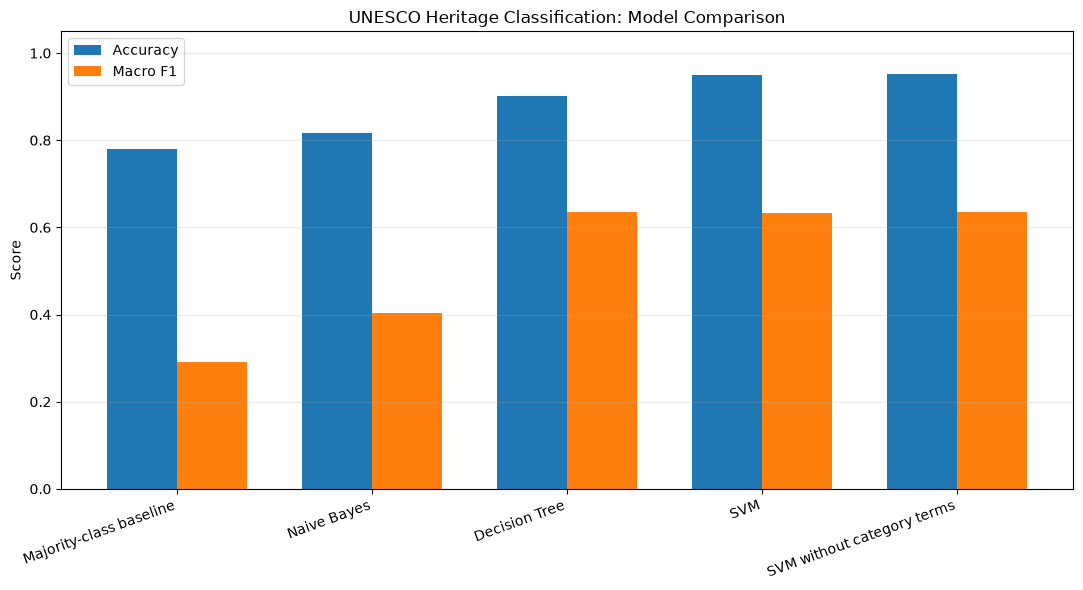

In [31]:
import matplotlib.pyplot as plt
from pathlib import Path
import numpy as np

# Create the figures folder in the project directory
current_dir = Path.cwd()

if current_dir.name == "notebooks":
    project_dir = current_dir.parent
else:
    project_dir = current_dir

figures_dir = project_dir / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

# Arrange the models in a consistent order
model_order = [
    "Majority-class baseline",
    "Naive Bayes",
    "Decision Tree",
    "SVM",
    "SVM without category terms"
]

plot_df = (
    final_results_df
    .set_index("Model")
    .loc[model_order]
    .reset_index()
)

# Create grouped bars
x = np.arange(len(plot_df))
width = 0.36

fig, ax = plt.subplots(figsize=(11, 6))

ax.bar(
    x - width / 2,
    plot_df["Accuracy"],
    width,
    label="Accuracy"
)

ax.bar(
    x + width / 2,
    plot_df["Macro F1"],
    width,
    label="Macro F1"
)

ax.set_title("UNESCO Heritage Classification: Model Comparison")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.05)
ax.set_xticks(x)
ax.set_xticklabels(
    plot_df["Model"],
    rotation=20,
    ha="right"
)

ax.legend()
ax.grid(axis="y", alpha=0.25)

fig.tight_layout()

fig.savefig(
    figures_dir / "model_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

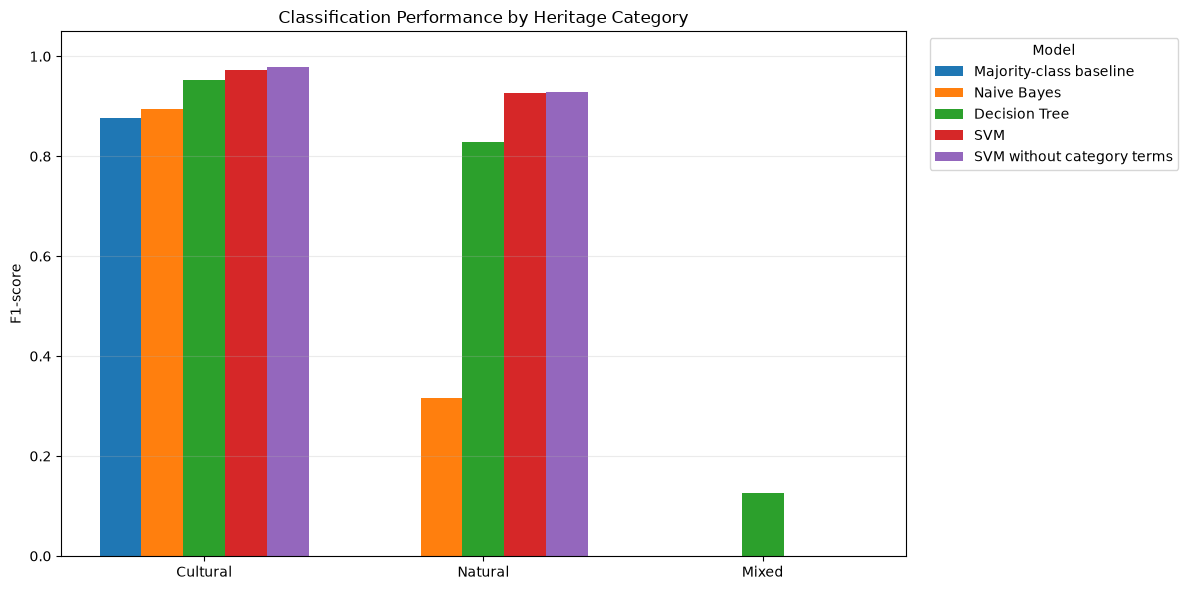

In [32]:
# Compare F1-scores across heritage categories

categories = [
    "Cultural F1",
    "Natural F1",
    "Mixed F1"
]

category_labels = [
    "Cultural",
    "Natural",
    "Mixed"
]

fig, ax = plt.subplots(figsize=(12, 6))

x = np.arange(len(category_labels))
width = 0.15
n_models = len(plot_df)

for i, (_, row) in enumerate(plot_df.iterrows()):

    offsets = x + (i - (n_models - 1) / 2) * width

    ax.bar(
        offsets,
        [row[column] for column in categories],
        width,
        label=row["Model"]
    )

ax.set_title("Classification Performance by Heritage Category")
ax.set_ylabel("F1-score")
ax.set_ylim(0, 1.05)
ax.set_xticks(x)
ax.set_xticklabels(category_labels)

ax.legend(
    title="Model",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

ax.grid(axis="y", alpha=0.25)

fig.tight_layout()

fig.savefig(
    figures_dir / "category_f1_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

## Results and Discussion

### Main Findings

Five classification approaches were compared using the same stratified train-test split: a majority-class baseline, Naive Bayes, Decision Tree, SVM, and SVM after removing selected category-related terms.

The best accuracy was 95.3%, achieved by the SVM experiment without selected category-related terms. The Decision Tree and this SVM experiment both achieved a macro F1-score of approximately 0.635.

However, classification performance varied substantially across heritage categories. The models performed well on Cultural properties, while the SVM models also performed well on Natural properties. The Mixed category remained difficult to classify.

The Decision Tree correctly identified one of the eight Mixed properties in the test set. The other approaches identified none.

### Implications for Cultural Heritage Information

These results suggest that automated text classification may help organize cultural heritage descriptions, but its reliability must be evaluated across individual categories.

The findings also demonstrate the importance of considering the relationship between descriptive text and official metadata labels. A model's prediction should not be treated as an authoritative determination of a site's heritage significance.

### Limitations

The evaluation used one 80/20 stratified train-test split. Only eight Mixed properties appeared in the test set, limiting the evidence available for assessing that category.

The category-related-word experiment produced only small changes in overall performance and did not improve Mixed classification. It does not establish why the models struggle with that category.

The results are preliminary and should not be assumed to generalize to other heritage datasets or descriptions.

### Conclusion

The project demonstrates a Python-based workflow for collecting UNESCO records, assessing data quality,
preprocessing descriptions, representing text with TF-IDF, and comparing classification algorithms.

The principal finding is that strong overall accuracy can coexist with poor performance on an underrepresented heritage category. This limitation is important when considering the use of automated classification in cultural heritage information organization.